# 11 — Final test: results
**Goal:** report the final test of the fatigue-aware controller (QMDP) on held-out people and images, and check that the test was run as planned.

This notebook **only reads saved results**. The final test itself was run once by [run_final_test.py](../scripts/run_final_test.py) on 22 Nov, with settings fixed beforehand in `outputs/final_test/settings.json`; it must not be rerun. If the final-test outputs are missing, the first cell stops with an error instead of producing anything.
Figures and tables come from [make_final_test_figures.py](../scripts/make_final_test_figures.py), so the report and this notebook show the same thing.

What was tested (all fixed before the run):
- **Stage 1** (information per human second; net reward = bits − λ·seconds, λ = 1): 33 cases × 15 policies × 500 matched sessions with **test annotators**, plus the full grid of 7,812 conditions.
- **Stage 2** (real classifier retrained from the simulated answers): 6 fatigue settings × 10 policies × 2 starting sizes × 20 seeds = 2,400 runs, scored on the **2,000 final-test images**.
- Statistics: paired bootstrap 95% intervals, sign-flip permutation p-values, Holm correction. Each Stage-2 setting has one main rival named in advance from the development results.

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib.util
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
final = project / 'outputs' / 'final_test'
figures = final / 'figures'
pd.set_option('display.max_columns', 30, 'display.width', 200)

def read(path):
    return pd.read_csv(path, keep_default_na=False, na_values=[''])

missing = [p for p in ['settings.json', 'final_report.json', 'stage1_complete.json', 'stage2_complete.json',
                       'grid_complete.json', 'stage1_tests.csv', 'stage2_runs.csv'] if not (final / p).exists()]
if missing:
    raise FileNotFoundError(f'Final-test outputs missing: {missing}. This notebook only reads them; it never runs the test.')

spec = importlib.util.spec_from_file_location('final_figures', project / 'scripts' / 'make_final_test_figures.py')
figs = importlib.util.module_from_spec(spec)
spec.loader.exec_module(figs)
NAMES = figs.NAMES
settings = json.loads((final / 'settings.json').read_text())
report = json.loads((final / 'final_report.json').read_text())
show = lambda name, width=900: display(Image(filename=str(figures / f'{name}.png'), width=width))

## 1. Was the test run as planned?
Checks: the settings were written before any run; each part ran once (its `started` and `complete` files); the code was the frozen code; every Stage-2 run used test annotators and was scored on all 2,000 final-test images.

In [2]:
src_now = hashlib.sha256(b''.join(p.read_bytes() for p in sorted((project / 'src').rglob('*.py')))).hexdigest()
frozen = json.loads((project / 'configs' / 'frozen_src.json').read_text())['src_sha256']
times = [('settings written', settings['written_utc'])]
for part in ['stage1', 'stage2', 'grid']:
    times.append((f'{part} started', json.loads((final / f'{part}_started.json').read_text())['started_utc']))
    times.append((f'{part} finished', json.loads((final / f'{part}_complete.json').read_text())['finished_utc']))
display(pd.DataFrame(times, columns=['event', 'UTC']))

runs = read(final / 'stage2_runs.csv')
configs = [json.loads((project / f / 'config.json').read_text()) for f in runs.run_folder]
curves = pd.read_csv(figures / 'curves_on_common_time_grid.csv.gz')
checks = {
    'settings written before the first part started': settings['written_utc'] < times[1][1],
    'src/ unchanged since frozen (now = frozen = settings)': src_now == frozen == settings['src_sha256'],
    'controller tested': settings['controller'],
    'Stage-2 runs': len(runs),
    'Stage-2 runs per setting × policy × size': int(runs.groupby(['setting', 'policy', 'seed_size']).size().unique()[0]),
    'Stage-2 seeds': f"{runs.seed.min()}–{runs.seed.max()}",
    'duplicate Stage-2 runs': int(runs.duplicated(['setting', 'policy', 'seed_size', 'seed']).sum()),
    'every run config has the frozen source hash': all(c['source_sha256'] == frozen for c in configs),
    'every run used test annotators': all(c['options']['annotators'] == 'test' for c in configs) and set(runs.annotators) == {'test'},
    'every run was scored on final-test images': all(c['options']['final_test'] for c in configs) and set(runs.evaluation_images) == {'final_test'},
    'all accuracies are whole counts out of 2,000 images': bool(np.allclose(curves.accuracy_percent * 20, np.round(curves.accuracy_percent * 20), atol=1e-3)),
    'Stage-1 cases / sessions / seed': f"{json.loads((final / 'stage1_complete.json').read_text())['cases']} / {settings['stage1']['sessions']} / {settings['stage1']['seed']}",
    'grid conditions': json.loads((final / 'grid_complete.json').read_text())['cases'],
}
display(pd.Series(checks, name='result').to_frame())
display(pd.Series(json.loads((final / 'stage2_complete.json').read_text())['rest_thresholds'], name='greedy + rest threshold (tuned on training people)').to_frame())

,event,UTC
0,settings written,2026-11-22T10:57:44.971059+00:00
1,stage1 started,2026-11-22T10:58:53.431133+00:00
2,stage1 finished,2026-11-22T11:00:33.211590+00:00
3,stage2 started,2026-11-22T11:01:44.426998+00:00
4,stage2 finished,2026-11-22T11:17:57.475537+00:00
5,grid started,2026-11-22T11:20:09.082725+00:00
6,grid finished,2026-11-22T12:36:11.284387+00:00


,result
settings written before the first part started,True
src/ unchanged since frozen (now = frozen = settings),True
controller tested,qmdp
Stage-2 runs,2400
Stage-2 runs per setting × policy × size,20
Stage-2 seeds,1000–1019
duplicate Stage-2 runs,0
every run config has the frozen source hash,True
every run used test annotators,True
every run was scored on final-test images,True


,greedy + rest threshold (tuned on training people)
None0,1.0
Markov1,1.5
Markov2,1.0
FALCON1,3.0
Lapse1:forced,1.5
Lapse1:forced_seconds,2.0


All checks pass. One cosmetic point: each Stage-2 run's `options` still carries the old text label *"QMDP provisional from Notebook 08; full Stage-1 grid pending"*. It is only a label copied from the default options; the controller was in fact chosen by the full grid (`settings.json` → `controller_selection`), and the label does not affect any result.

In [3]:
figs.main()   # remakes every figure and tables.md from the saved outputs (no experiments are run)

wrote fig1_stage2_primary_comparisons
wrote fig2_stage2_accuracy_curves_50_labels
wrote fig2_stage2_accuracy_curves_200_labels
wrote fig3_stage2_all_rivals
wrote fig4_stage1_all_cases
wrote fig5_stage1_advantage_by_beta
wrote fig6_stage2_answers_and_errors
wrote fig7_full_grid_rates
wrote fig8_development_vs_final_test
development vs test pairs: (364, 90)
wrote tables.md


## 2. Stage 1: information per human second
### H1 — with no fatigue, QMDP should do as well as the best required baseline

In [4]:
h1 = report['stage1']['h1']
t1 = read(final / 'stage1_tests.csv')
print(f"Best required baseline: {NAMES[h1['best_required_baseline']]}; QMDP minus it = {h1['qmdp_minus_best']:.2f} (SE {h1['se']:.2f})")
display(t1[t1.case == 'no_fatigue'].assign(rival=lambda d: d.rival.map(NAMES))[['rival', 'difference', 'ci_low', 'ci_high', 'p_holm']].round(3))

Best required baseline: Ignores fatigue; QMDP minus it = 0.00 (SE 0.00)


,rival,difference,ci_low,ci_high,p_holm
234,Always full,24.980,23.157,26.989,0.0
235,Always 2-choice,32.854,31.569,34.033,0.0
236,Always verify,36.658,33.672,39.438,0.0
237,Random type,31.595,30.689,32.466,0.0
238,Alternating,31.587,30.658,32.490,0.0
239,Exp. decay,770.488,765.027,776.062,0.0
240,Gap workload,24.980,23.157,26.989,0.0
241,Ignores fatigue,0.000,0.000,0.000,1.0
242,Greedy,0.000,0.000,0.000,1.0
243,Greedy + rest,0.000,0.000,0.000,1.0


**Observed:** H1 holds. With no fatigue QMDP makes exactly the same choices as Ignores fatigue, Greedy, Greedy + rest and the grid planner (difference 0.0), and it is clearly ahead of the fixed-format baselines.

### H2 — at β ≥ 1, QMDP should beat all eight required baselines (B1–B8) after Holm correction

In [5]:
h2 = read(final / 'stage1_h2.csv')
REQUIRED = ['full', 'two_choice', 'verify', 'random', 'alternating', 'exp_decay', 'gap_workload', 'blind']
print('Brief definition (Markov and FALCON, beta >= 1):', report['stage1']['h2_markov_falcon_beta_ge_1_holm'])
display(h2.groupby('family').beats_all_B1_B8_holm.agg(['sum', 'count']).rename(columns={'sum': 'cases beating all B1-B8', 'count': 'cases'}))
misses = []
for _, row in h2[~h2.beats_all_B1_B8_holm].iterrows():
    sub = t1[(t1.case == row.case) & t1.rival.isin(REQUIRED)]
    failed = sub[~((sub.p_holm < .05) & (sub.difference > 0))]
    misses.append({'case': row.case, 'not clearly beaten': ', '.join(f"{NAMES[r.rival]} ({r.difference:+.1f})" for _, r in failed.iterrows())})
display(pd.DataFrame(misses))

Brief definition (Markov and FALCON, beta >= 1): {'FALCON': '1/3', 'Markov': '16/17'}


,cases beating all B1-B8,cases
family,,
control,0,2
core_FALCON,2,4
core_Lapse,0,4
core_Markov,4,4
lapse_seconds,0,4
no_fatigue,0,1
sensitivity,11,12
stress,2,2


,case,not clearly beaten
0,lapse_seconds_without_fatigue,"Always 2-choice (-55.5), Always verify (-154.0..."
1,lapse_without_fatigue,"Always 2-choice (-25.8), Always verify (-83.4)..."
2,FALCON_beta_2,Always verify (-0.1)
3,FALCON_beta_3,Always verify (-0.7)
4,Lapse_beta_0.5,Always verify (-29.2)
5,Lapse_beta_1,Always verify (-26.2)
6,Lapse_beta_2,Always verify (-21.0)
7,Lapse_beta_3,Always verify (-17.3)
8,Lapse_seconds_beta_0.5,Always verify (-59.8)
9,Lapse_seconds_beta_1,Always verify (-54.7)


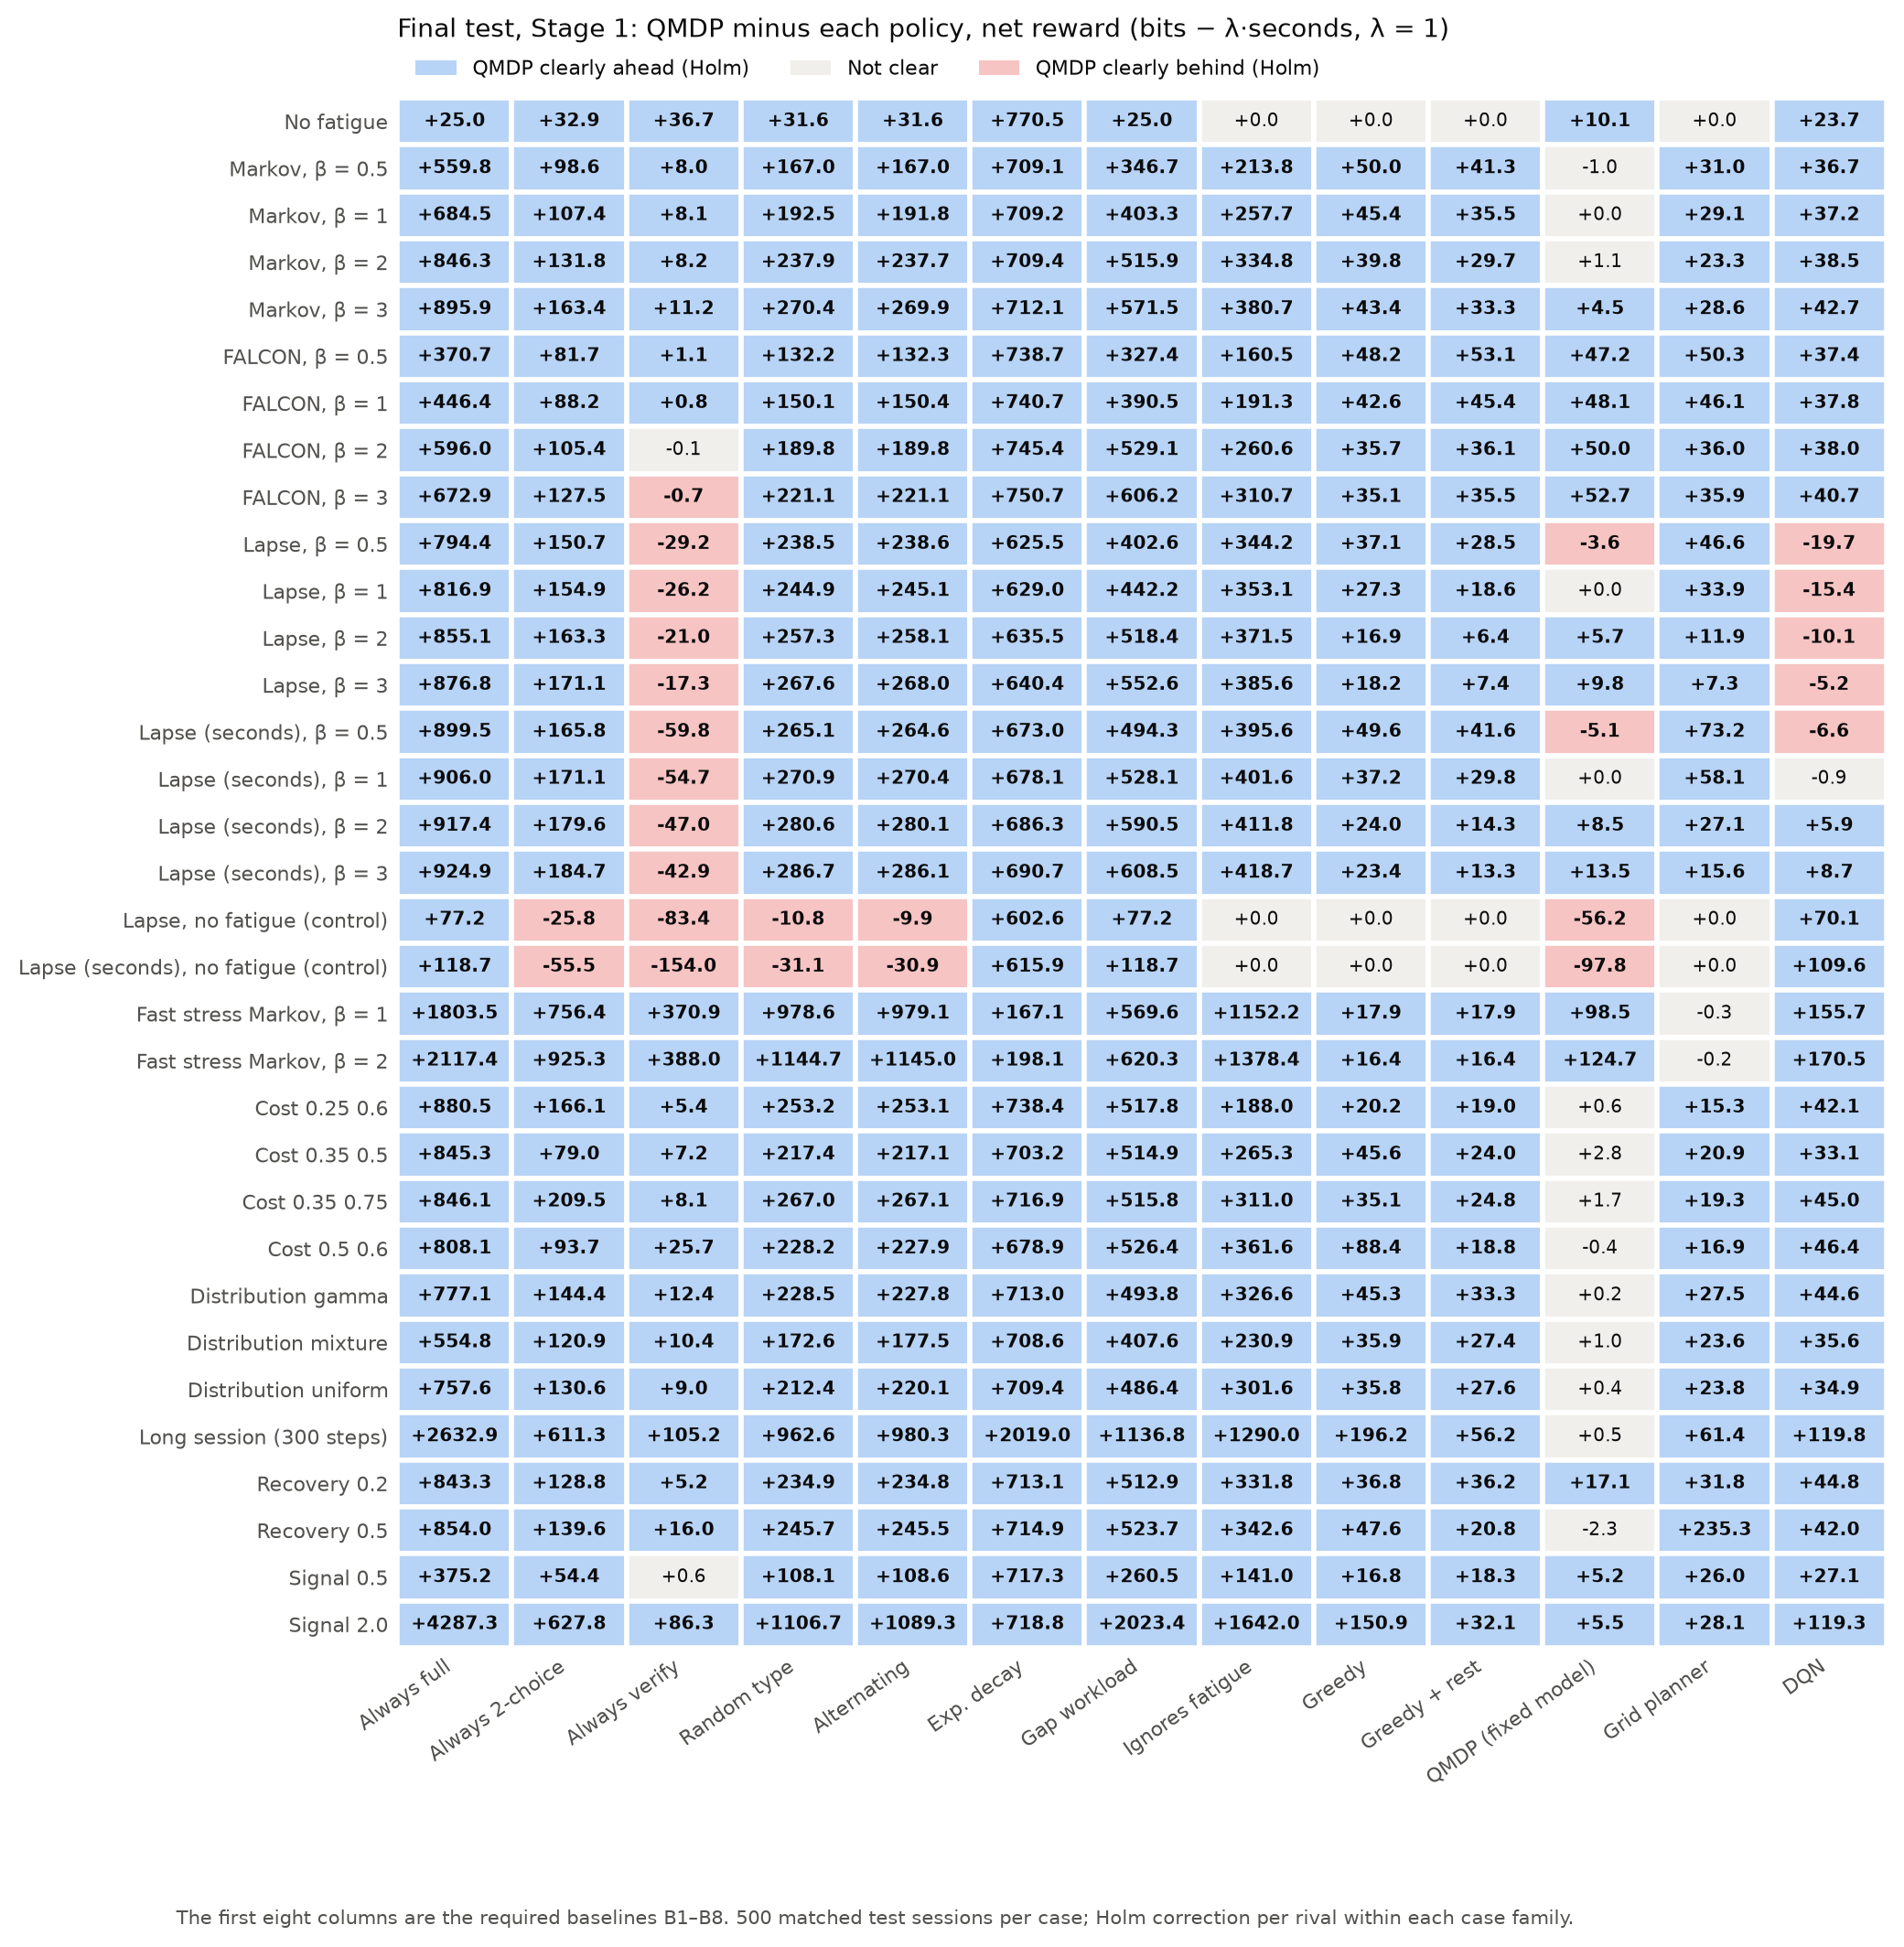

In [6]:
show('fig4_stage1_all_cases', 950)

**Observed:** Markov fatigue: 16 of 17 cases (the miss is the weak-signal case, where QMDP is only +0.6 ahead of Always verify). FALCON: 1 of 3 at β ≥ 1; Always verify ties QMDP at β = 2 and is clearly ahead at β = 3. Lapse: 0 of 8, in both onset versions; Always verify is clearly ahead every time, and DQN is ahead at low β.

**Interpretation:** QMDP wins where its fatigue model is right (Markov). In FALCON, QMDP asks the cheap verify question almost every time, so it and Always verify nearly coincide (the ceiling effect seen in development). In Lapse, fatigue does not drive the errors, so QMDP's tracking adds nothing and its extra answers after the lapse cost it.

### H3 — QMDP's lead over greedy should grow with fatigue strength β

Markov, QMDP minus greedy at beta 0.5, 1, 2, 3: [49.998, 45.389, 39.796, 43.448]
slope per beta step: -2.70, 95% CI [-4.50, -1.02]


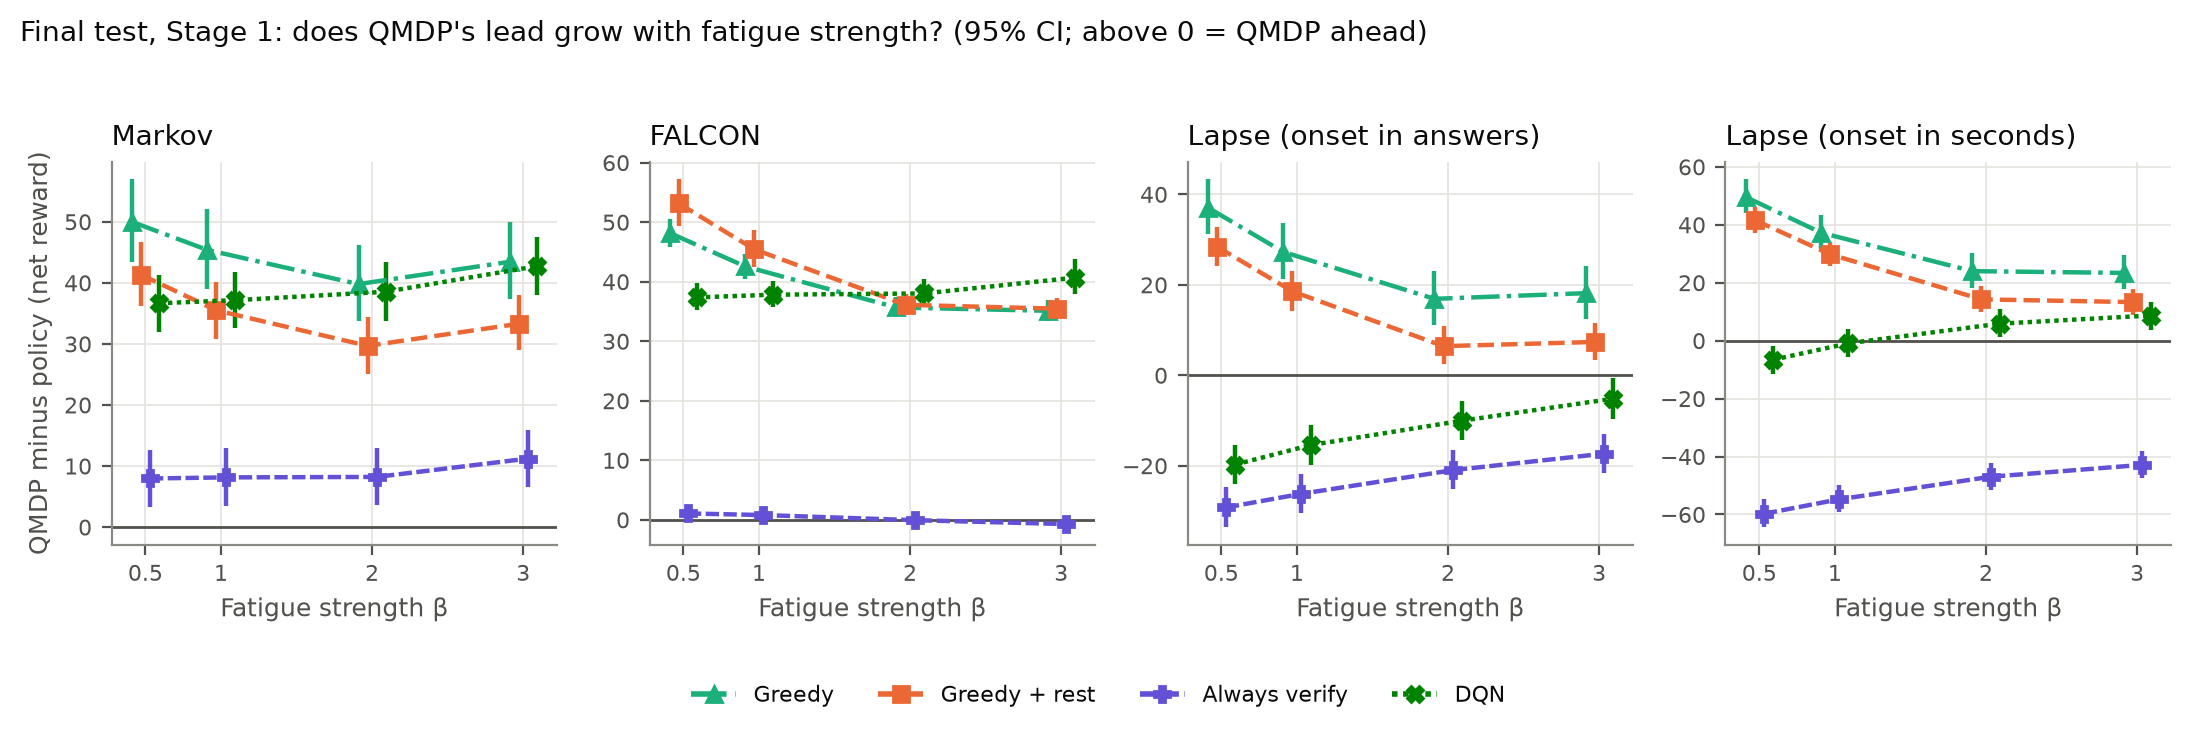

In [7]:
h3 = report['stage1']['h3_markov']
print('Markov, QMDP minus greedy at beta 0.5, 1, 2, 3:', h3['qmdp_minus_greedy_beta_0.5_1_2_3'])
print(f"slope per beta step: {h3['slope_per_beta']:.2f}, 95% CI [{h3['slope_ci'][0]:.2f}, {h3['slope_ci'][1]:.2f}]")
show('fig5_stage1_advantage_by_beta', 1000)

**Observed:** H3 fails. The lead over greedy *shrinks* as β grows (slope −2.7 per step, CI excludes 0), the same direction as in development.

**Interpretation:** at λ = 1 the room for improvement over greedy (oracle headroom, E4) is roughly flat in β, so there is no growing gap for QMDP to capture.

### Robustness — QMDP against greedy when the true fatigue differs from QMDP's model

In [8]:
rob = read(final / 'robustness_tests.csv')
display(rob[['condition', 'rival', 'difference', 'ci_low', 'ci_high', 'p_holm']].round(3))
print('Clearly better after Holm:', report['stage1']['robustness_beats_greedy_holm'])

,condition,rival,difference,ci_low,ci_high,p_holm
0,FALCON_world,myopic,-10.643,-13.851,-7.556,0.0
1,Lapse_world,myopic,16.901,11.019,23.122,0.0
2,half_as_fast,myopic,16.911,12.978,20.953,0.0
3,stronger_fatigue,myopic,43.563,37.260,50.176,0.0
4,twice_as_fast,myopic,81.851,73.421,90.381,0.0
5,weaker_fatigue,myopic,38.370,32.652,44.419,0.0


Clearly better after Holm: 5/6


**Observed:** QMDP stays clearly ahead of greedy in 5 of 6 misspecified worlds; it is clearly behind in the FALCON world (−10.6).

### Full grid (7,812 conditions; descriptive rates, no correction)

Beats all of B1-B8 at beta >= 1: {'FALCON': '1146/1944', 'Lapse': '702/1944', 'Markov': '1705/1944'}


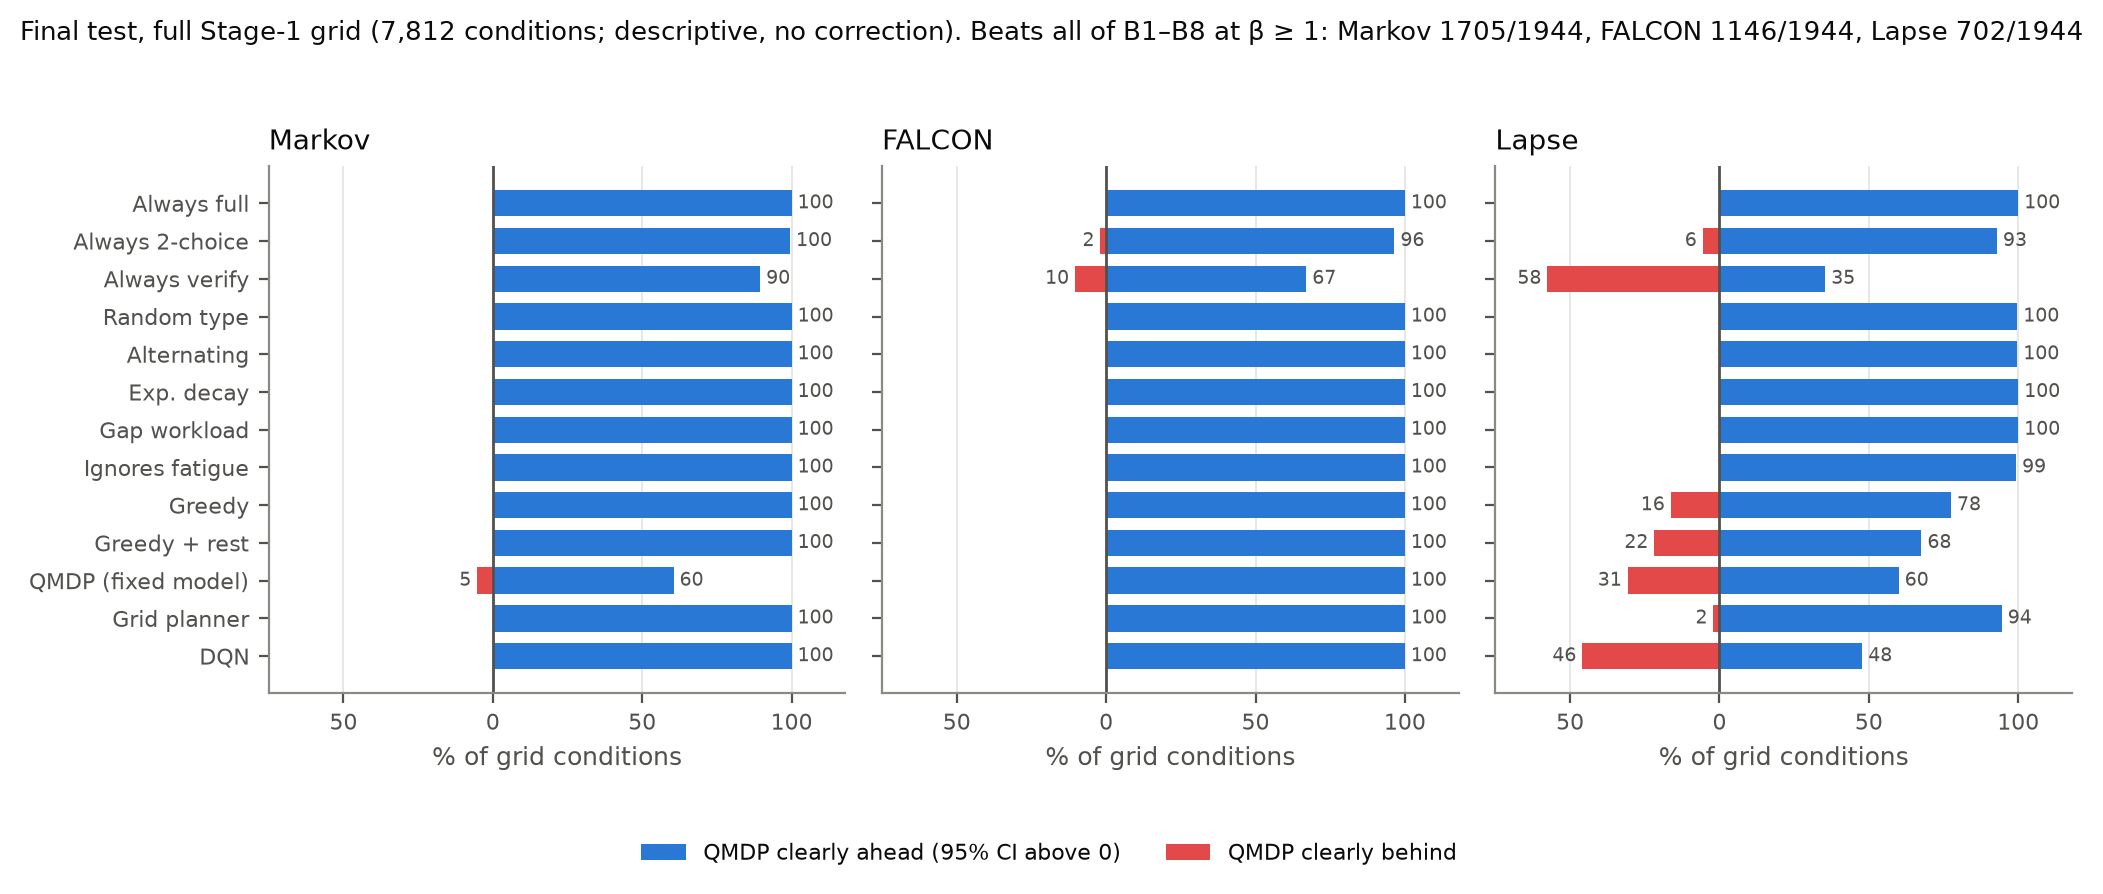

In [9]:
print('Beats all of B1-B8 at beta >= 1:', report['grid']['h2_rate_beta_ge_1_unadjusted'])
show('fig7_full_grid_rates', 1000)

**Observed:** the grid repeats the core cases: QMDP is clearly ahead of nearly every rival in nearly every Markov and FALCON condition, except Always verify in FALCON (ahead in 67%) and the deployable QMDP in Markov (60%). In Lapse it is clearly behind Always verify in 58% of conditions and behind DQN in 46%.

## 3. Stage 2: does the classifier learn better?
### The 12 main comparisons (rival named in advance; Holm across all 12)

,setting,seed_size,rival,difference,ci_low,ci_high,p,p_holm_primary_family,result
0,FALCON1,50,Greedy,0.0612,-0.3521,0.5049,0.7863,1.0000,not clear
1,FALCON1,200,Greedy,0.2803,0.0150,0.5350,0.0506,0.4046,not clear
2,Lapse1:forced,50,Ignores fatigue,-4.3439,-5.6938,-3.0234,0.0000,0.0002,clearly worse
3,Lapse1:forced,200,Ignores fatigue,-4.5820,-5.4064,-3.7286,0.0000,0.0000,clearly worse
4,Lapse1:forced_seconds,50,Always 2-choice,-1.0526,-2.9395,0.9230,0.3194,1.0000,not clear
5,Lapse1:forced_seconds,200,Always 2-choice,-1.8419,-2.7099,-0.9256,0.0011,0.0110,clearly worse
6,Markov1,50,Greedy + rest,0.0348,-0.4855,0.5983,0.9044,1.0000,not clear
7,Markov1,200,Greedy + rest,-0.2747,-0.5499,-0.0234,0.0606,0.4244,not clear
8,Markov2,50,Greedy + rest,0.0741,-0.4809,0.6556,0.8067,1.0000,not clear
9,Markov2,200,Greedy + rest,-0.4551,-0.7132,-0.2042,0.0033,0.0300,clearly worse


Clearly better: 0 | clearly worse: 4


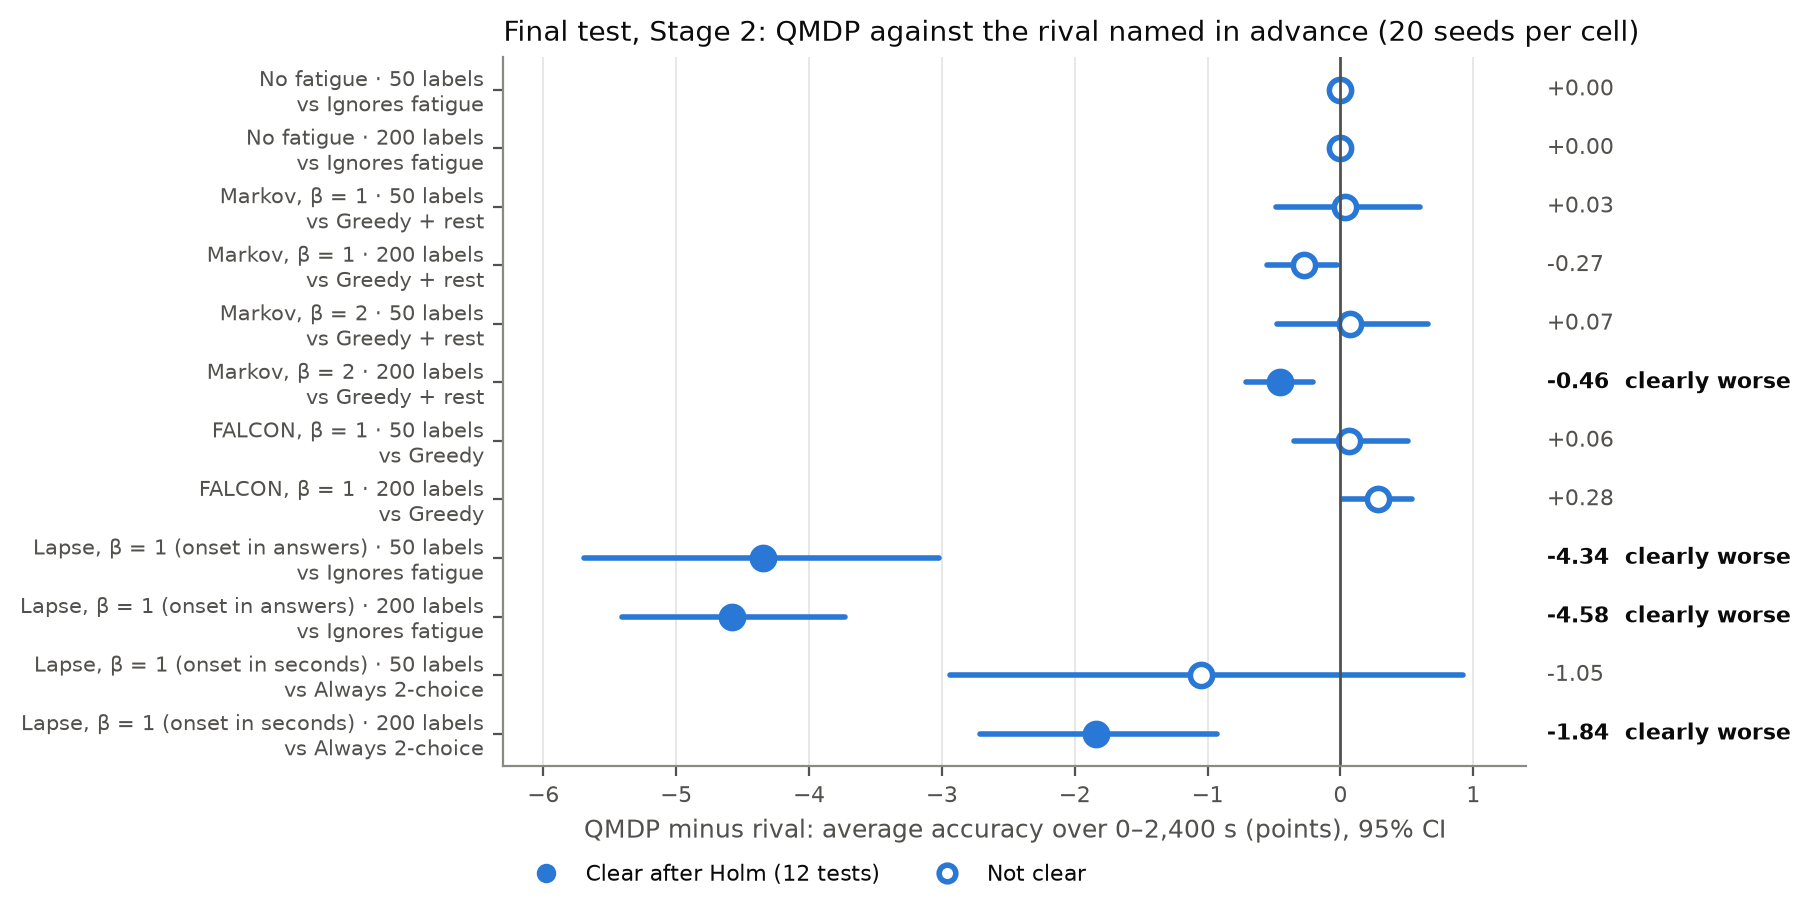

In [10]:
p = read(final / 'stage2_primary.csv')
p['rival'] = p.rival.map(NAMES)
p['result'] = np.where(p.p_holm_primary_family < .05, np.where(p.difference > 0, 'clearly better', 'clearly worse'), 'not clear')
display(p[['setting', 'seed_size', 'rival', 'difference', 'ci_low', 'ci_high', 'p', 'p_holm_primary_family', 'result']].round(4))
print('Clearly better:', report['stage2']['qmdp_clearly_better_after_holm'], '| clearly worse:', report['stage2']['qmdp_clearly_worse_after_holm'])
show('fig1_stage2_primary_comparisons', 850)

**Observed:** 0 of 12 clearly better, 4 clearly worse (both Lapse onset-in-answers cells, Lapse onset-in-seconds at 200 labels, and Markov β = 2 at 200 labels against Greedy + rest), 8 not distinguishable.

Two cells (Markov β = 1 and FALCON at 200 labels) have a bootstrap interval that just excludes 0 but a permutation p of about 0.05–0.06. They count as not clear, because the decision rule fixed in advance uses the Holm-adjusted permutation p-value.

### Against every rival

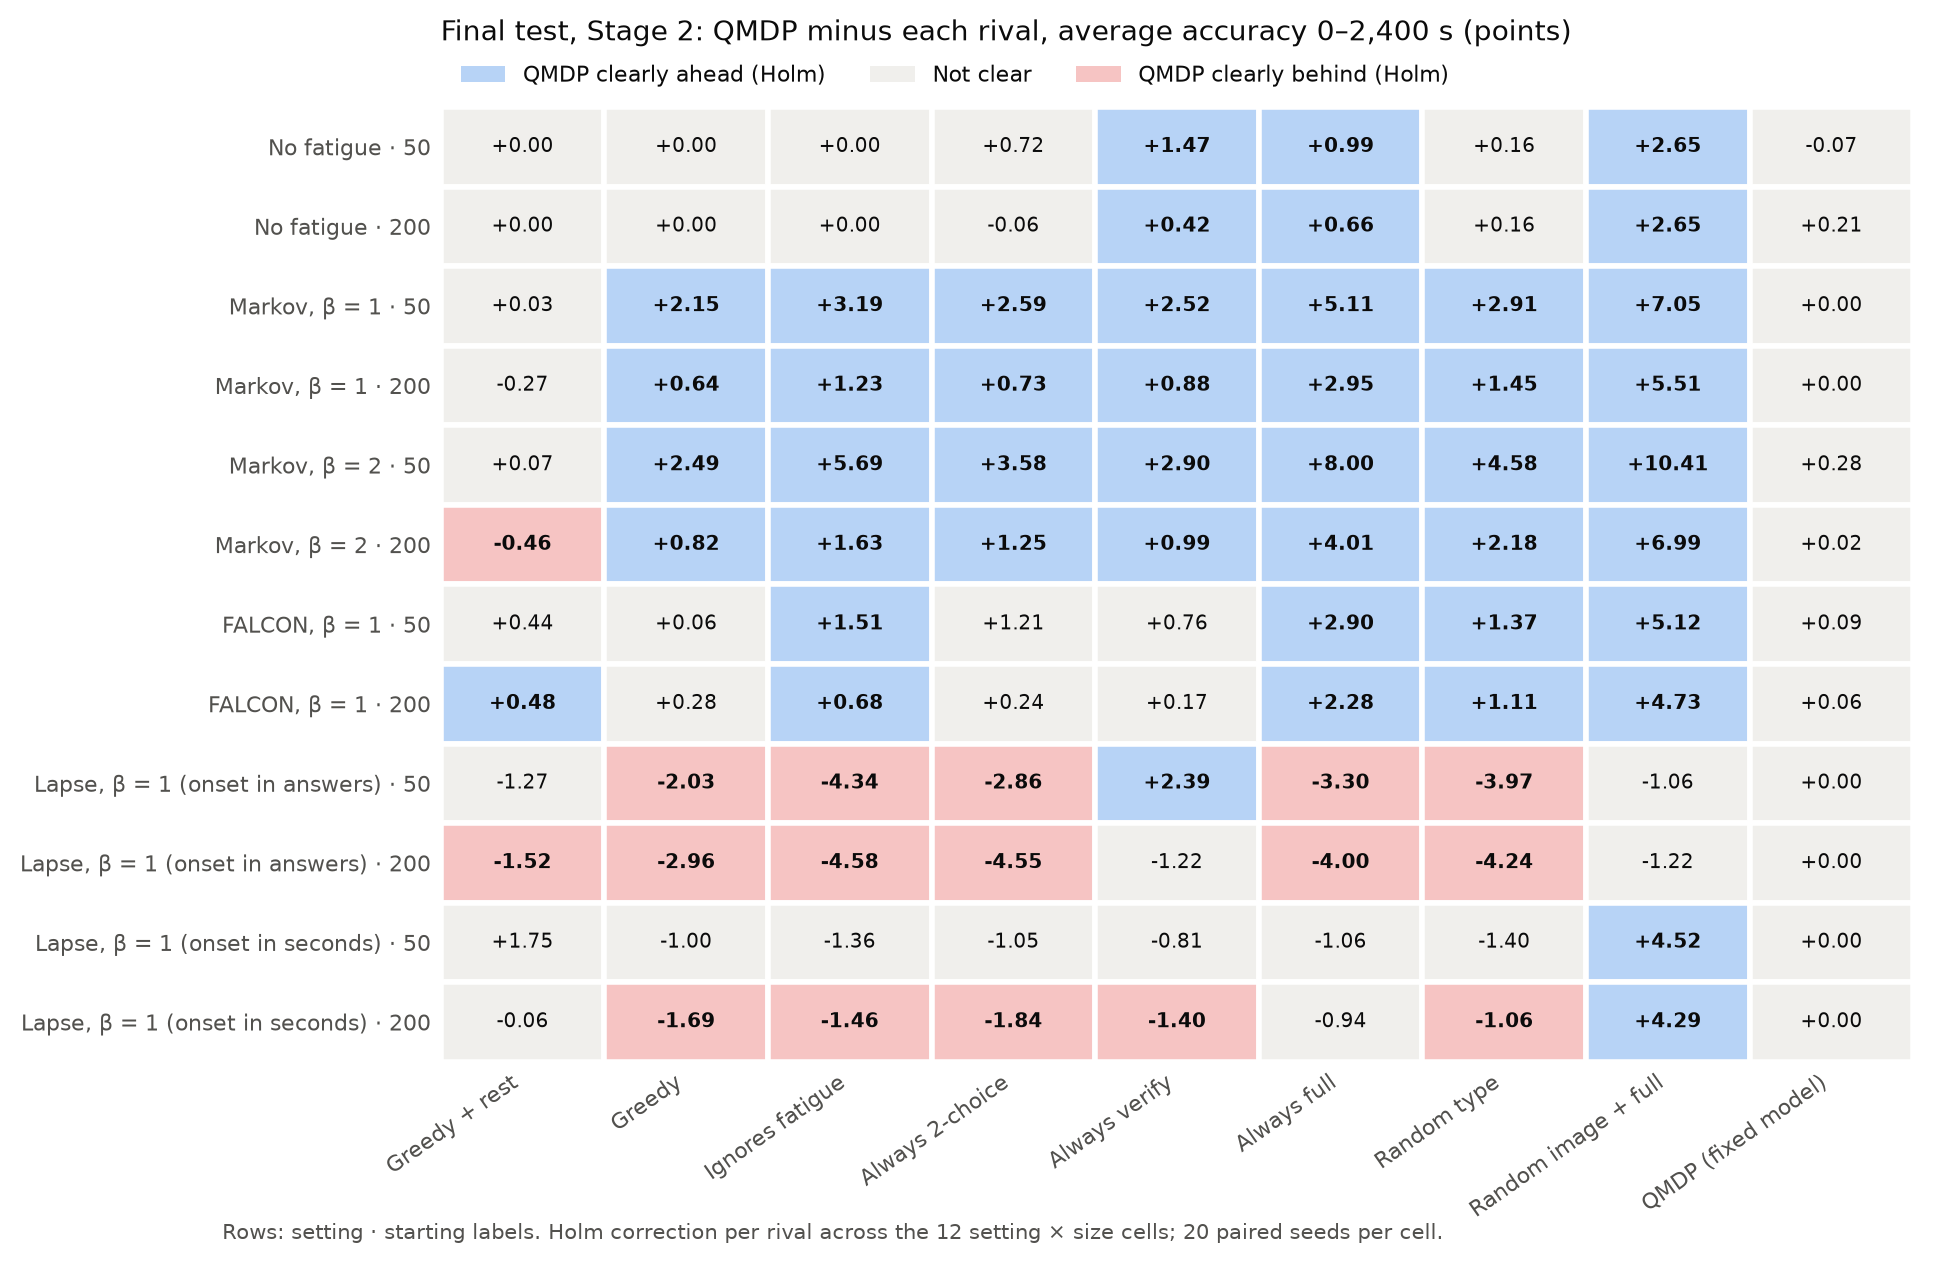

In [11]:
show('fig3_stage2_all_rivals', 950)

**Observed:** with Markov fatigue QMDP is clearly ahead of every rival except Greedy + rest (and its own fixed-model version). In FALCON it is clearly ahead of Ignores fatigue, Always full and the random policies (and of Greedy + rest at 200 labels), and level with the rest. In both Lapse worlds it is clearly behind five or six of the nine rivals at 200 labels.

### Accuracy over time

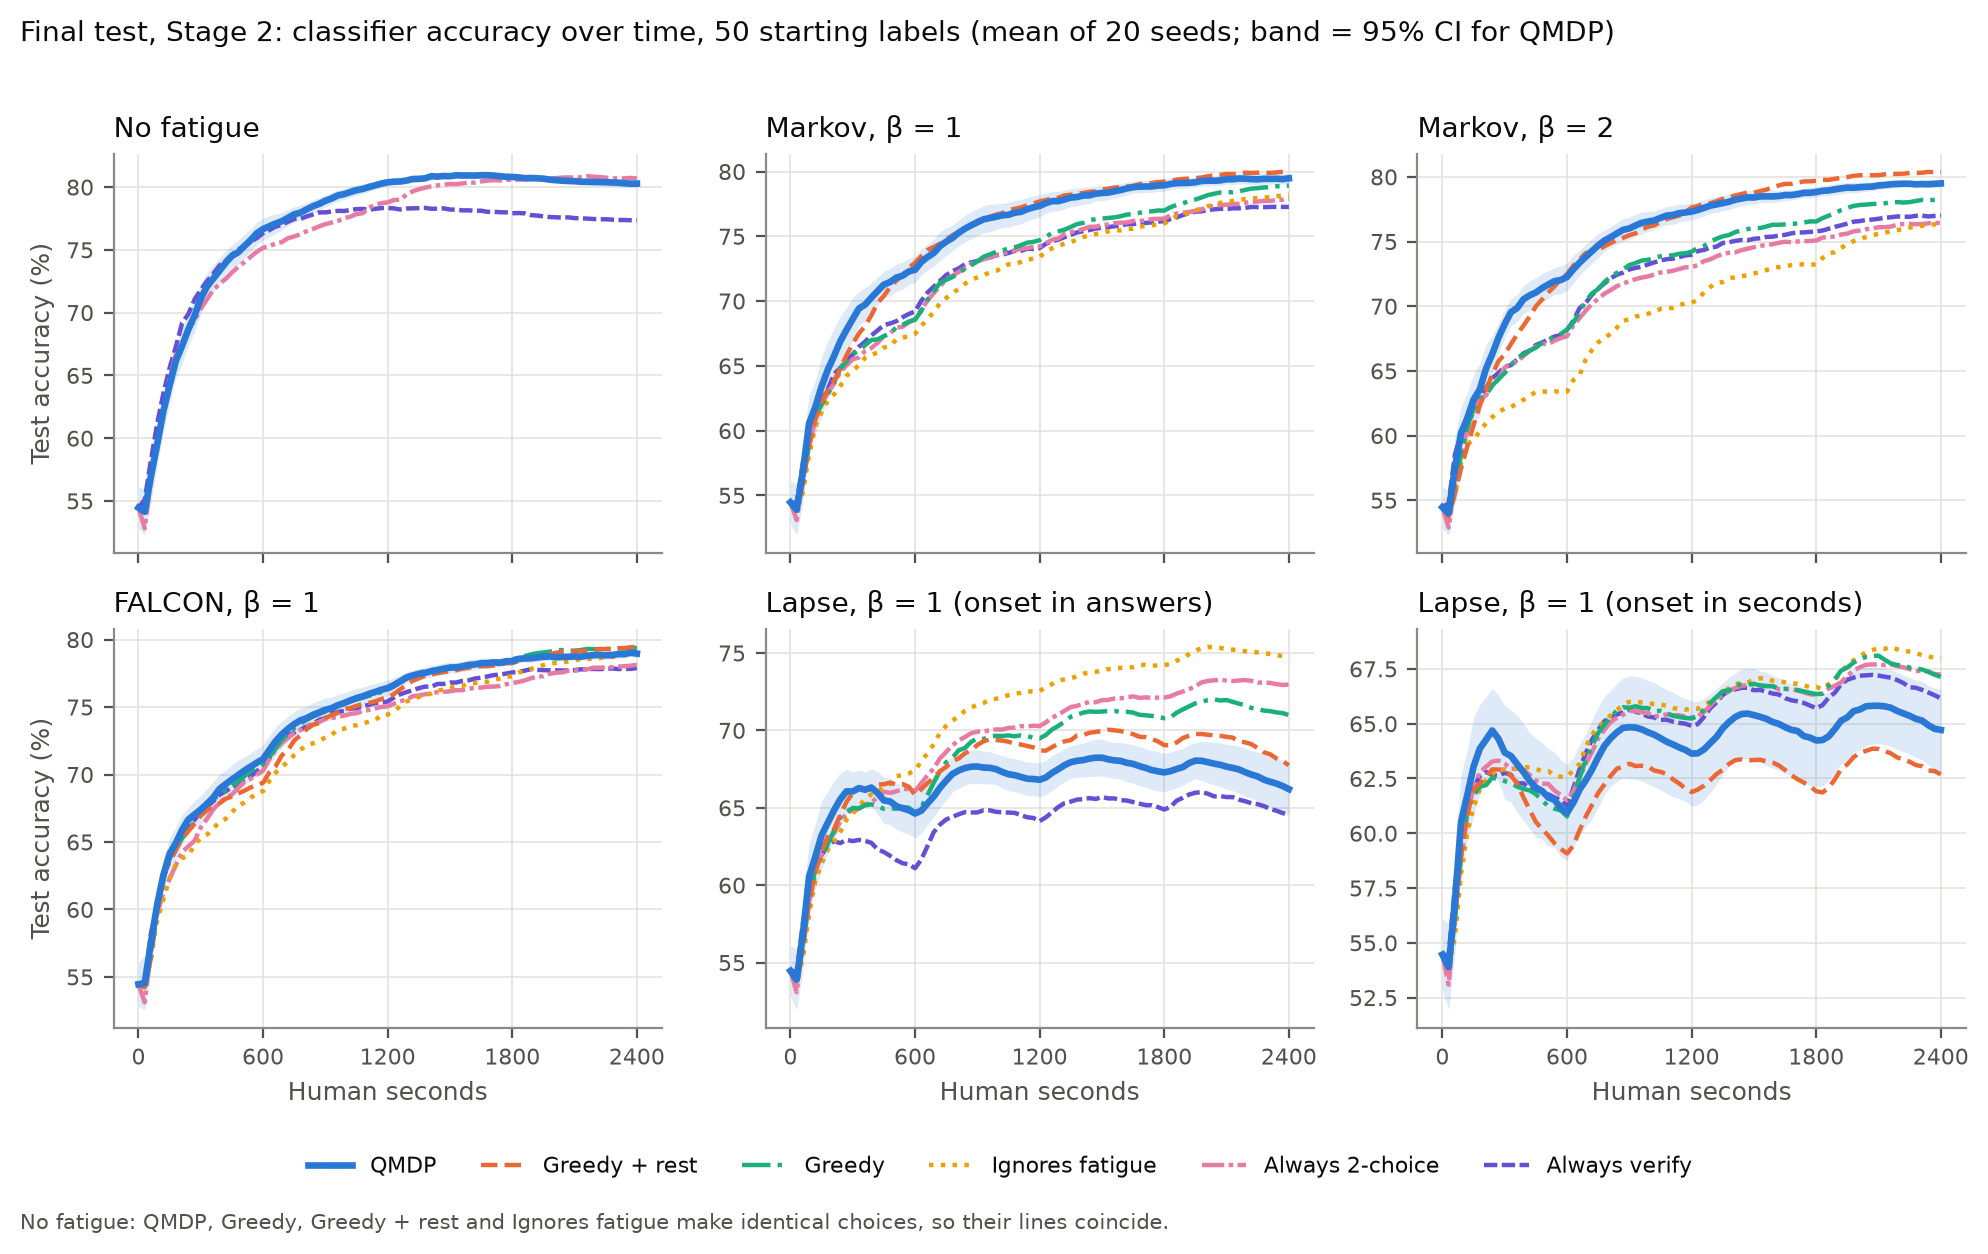

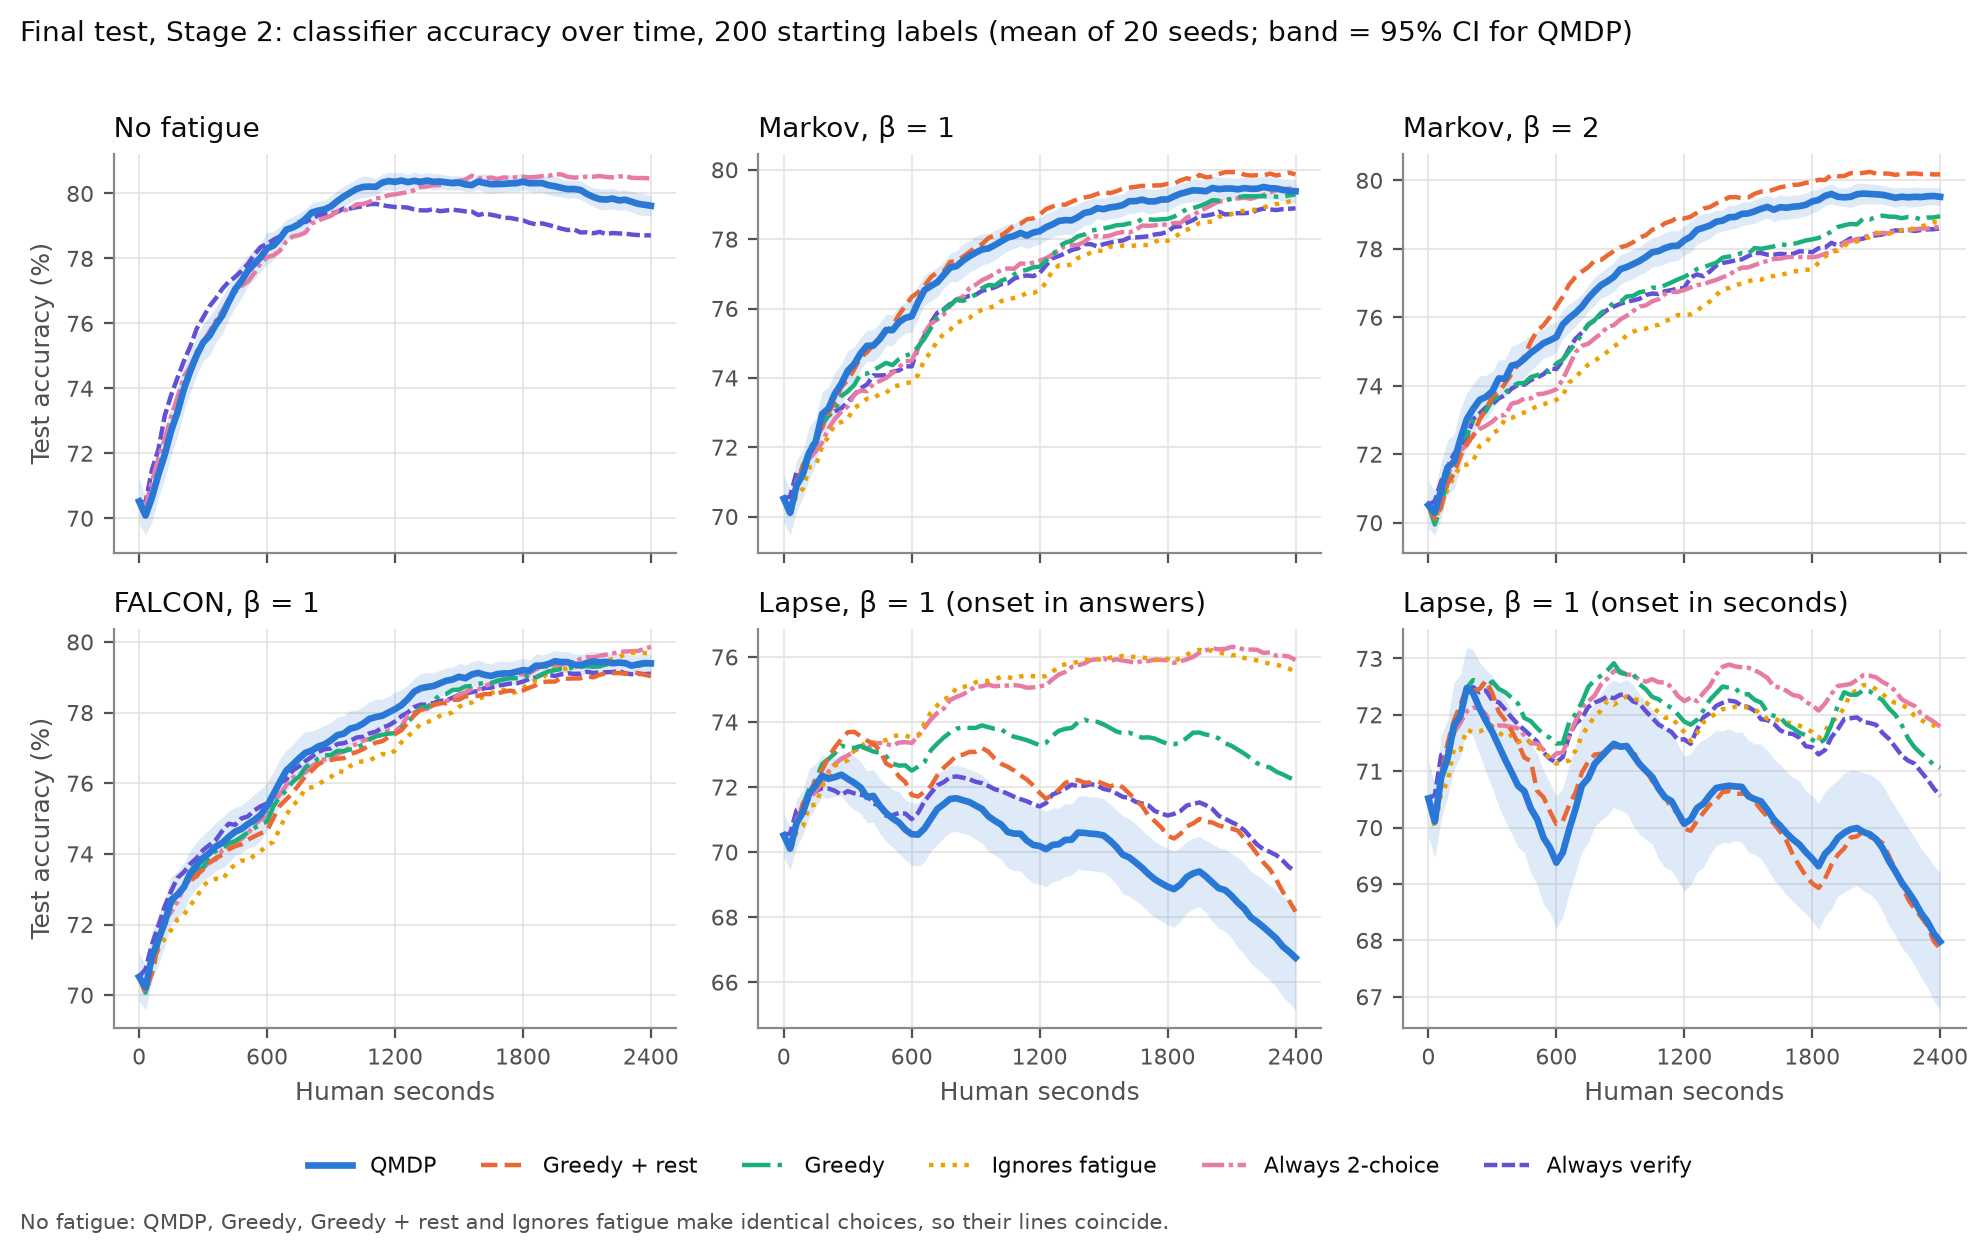

In [12]:
show('fig2_stage2_accuracy_curves_50_labels', 1000)
show('fig2_stage2_accuracy_curves_200_labels', 1000)

### Why: how many answers each policy gets, and how many are wrong

policy,Always 2-choice,Always verify,Greedy,Greedy + rest,Ignores fatigue,QMDP
setting,,,,,,
FALCON1,1130.0,2064.0,1884.0,1729.0,1389.0,2041.0
Lapse1:forced,1000.0,1714.0,1535.0,2008.0,1110.0,2054.0
Lapse1:forced_seconds,966.0,1705.0,1506.0,1898.0,917.0,2033.0
Markov1,1043.0,1843.0,1671.0,2187.0,1199.0,2157.0
Markov2,1024.0,1805.0,1662.0,2269.0,1188.0,2179.0
None0,2377.0,3742.0,3515.0,3515.0,3515.0,3515.0


policy,Always 2-choice,Always verify,Greedy,Greedy + rest,Ignores fatigue,QMDP
setting,,,,,,
FALCON1,5.1,4.3,4.7,4.6,6.0,4.1
Lapse1:forced,19.7,27.1,25.6,31.4,22.8,30.9
Lapse1:forced_seconds,33.0,26.0,29.3,33.2,35.2,29.7
Markov1,5.5,4.7,5.5,3.2,7.1,3.6
Markov2,10.5,6.0,6.5,2.5,11.6,4.2
None0,2.3,1.3,1.6,1.6,1.6,1.6


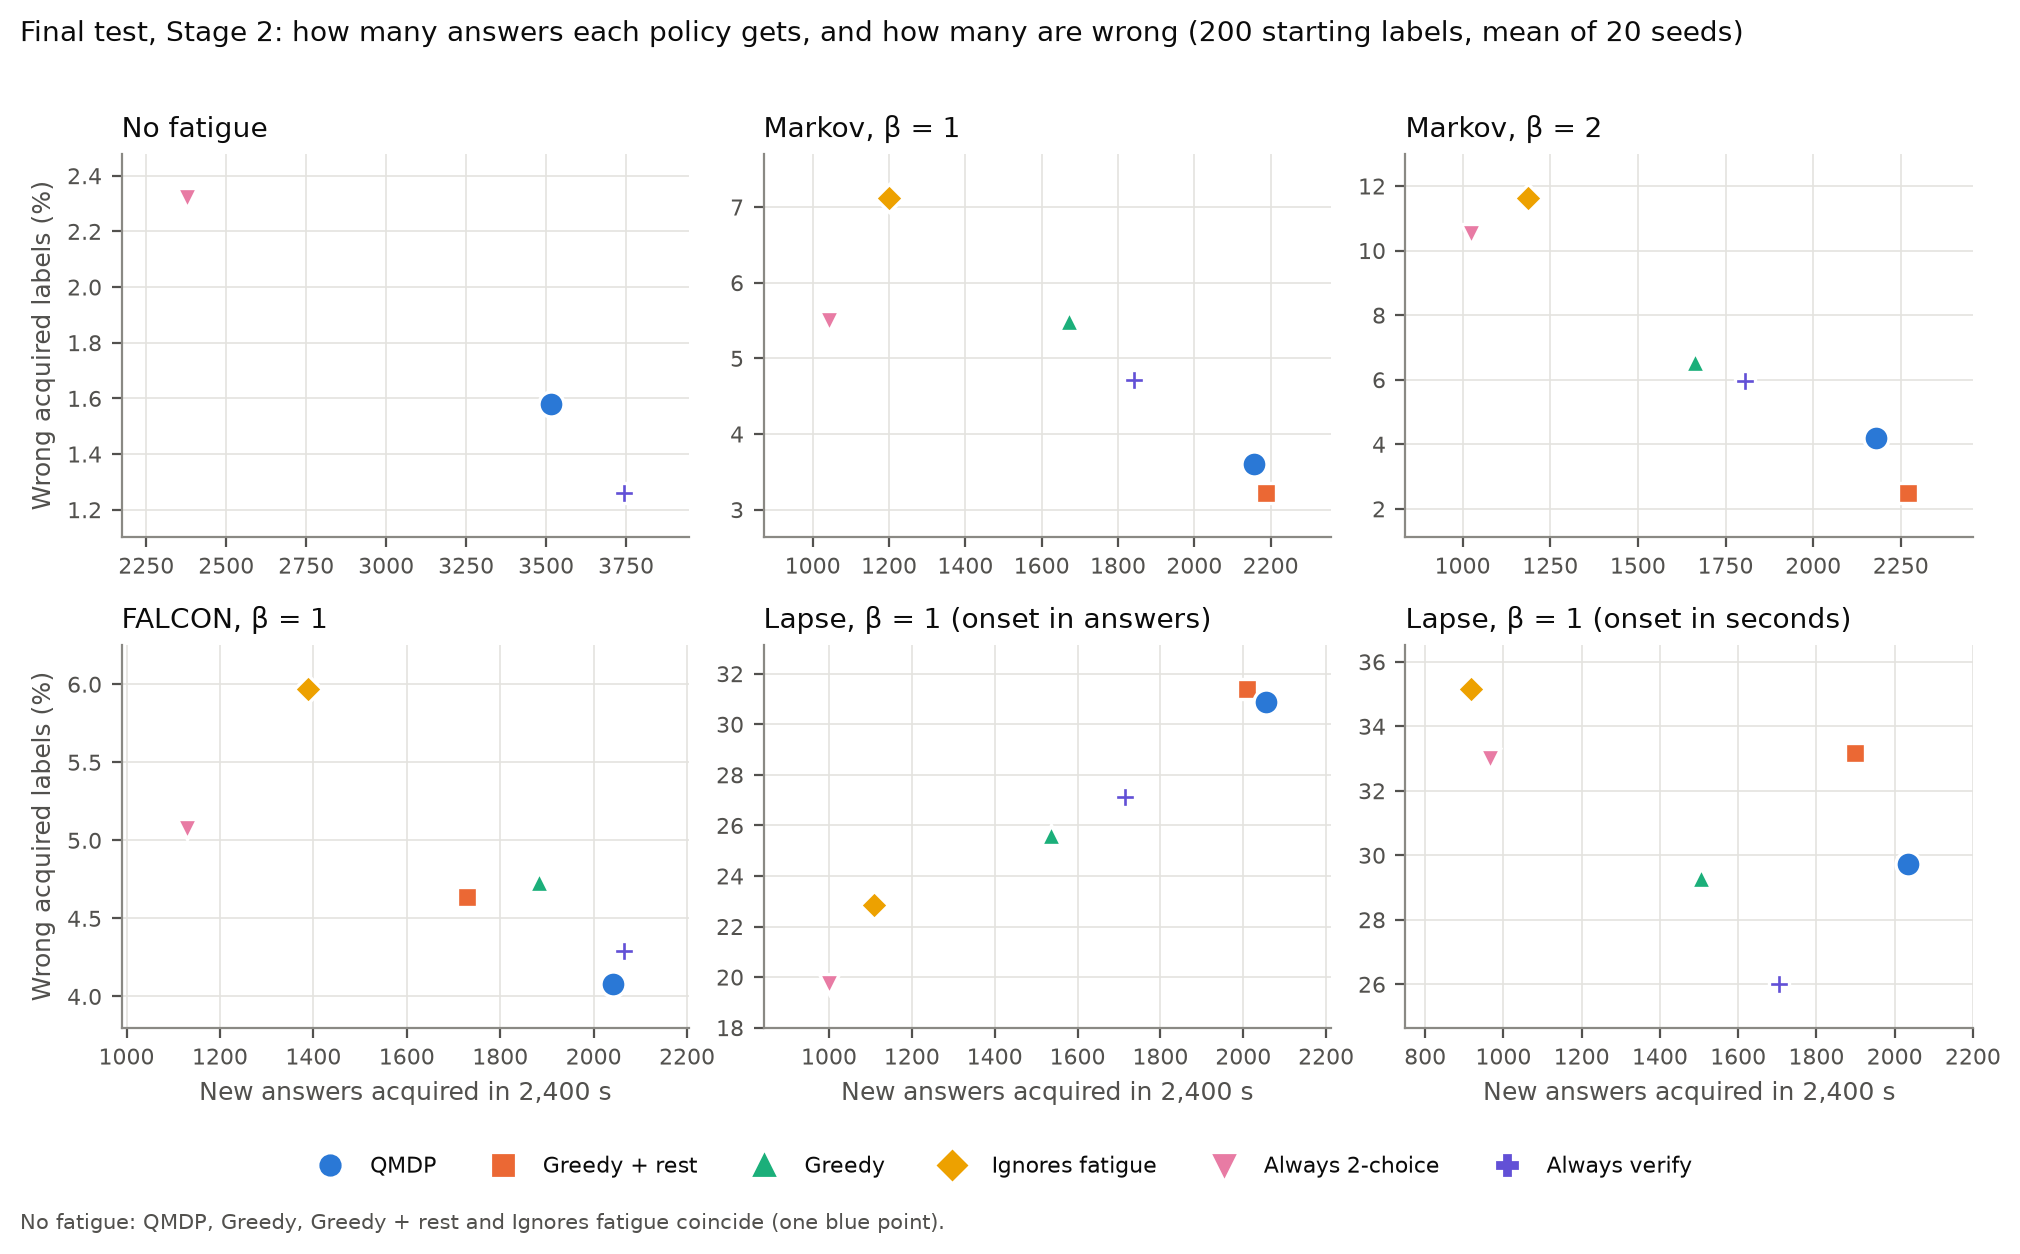

In [13]:
s = read(final / 'stage2_summary.csv')
keep = ['qmdp', 'rest_threshold', 'myopic', 'blind', 'two_choice', 'verify']
m = s[(s.seed_size == 200) & s.policy.isin(keep)].assign(policy=lambda d: d.policy.map(NAMES),
        wrong_percent=lambda d: 100 * d.acquired_error_rate)
display(m.pivot(index='setting', columns='policy', values='acquired_answers').round(0))
display(m.pivot(index='setting', columns='policy', values='wrong_percent').round(1))
show('fig6_stage2_answers_and_errors', 1000)

**Observed:** with Markov fatigue QMDP and Greedy + rest both collect about 2,100–2,300 answers with 2–4% wrong, against about 1,200 answers with 7–12% wrong for Ignores fatigue. In Lapse with the onset counted in answers, QMDP and Greedy + rest collect the most answers but about 31% are wrong, against 23% for Ignores fatigue. With the onset counted in seconds, the error rates are closer (26–35%) and QMDP's loss is smaller.

**Interpretation:** pausing is what keeps fatigue and label noise down in Markov, and the simple rest rule captures nearly all of that benefit (consistent with the E3 ablations). In Lapse, the extra answers come after the lapse and add mostly noise; counting the onset in seconds removes part of this throughput penalty.

### Time to reach 75% and 80% accuracy (descriptive only)

In [14]:
tt = read(final / 'stage2_tests.csv')
tt = tt[tt.metric.str.startswith('seconds_saved')]
display(tt.assign(rival=lambda d: d.rival.map(NAMES))[['metric', 'setting', 'seed_size', 'rival', 'pairs', 'difference', 'p', 'p_holm']].round(3))

,metric,setting,seed_size,rival,pairs,difference,p,p_holm
18,seconds_saved_t75,FALCON1,50,Greedy,20,22.402,0.650,0.650
19,seconds_saved_t80,FALCON1,50,Greedy,1,416.865,1.000,1.000
38,seconds_saved_t75,FALCON1,200,Greedy,20,45.199,0.132,0.265
39,seconds_saved_t80,FALCON1,200,Greedy,1,380.265,1.000,1.000
58,seconds_saved_t75,Lapse1:forced,50,Ignores fatigue,0,NaN,1.000,1.000
59,seconds_saved_t80,Lapse1:forced,50,Ignores fatigue,0,NaN,1.000,1.000
78,seconds_saved_t75,Lapse1:forced,200,Ignores fatigue,5,-96.509,0.625,1.000
79,seconds_saved_t80,Lapse1:forced,200,Ignores fatigue,0,NaN,1.000,1.000
98,seconds_saved_t75,Lapse1:forced_seconds,50,Always 2-choice,0,NaN,1.000,1.000
99,seconds_saved_t80,Lapse1:forced_seconds,50,Always 2-choice,0,NaN,1.000,1.000


Positive = QMDP reaches the target sooner. A pair counts only when both policies reach the target. The 75% target is reached in all 20 pairs in Markov, FALCON and no fatigue, but the 80% target and both Lapse targets in only 0–11 pairs. No difference is clear after Holm, so time-to-target adds no evidence either way.

## 4. Do the final-test results match development?

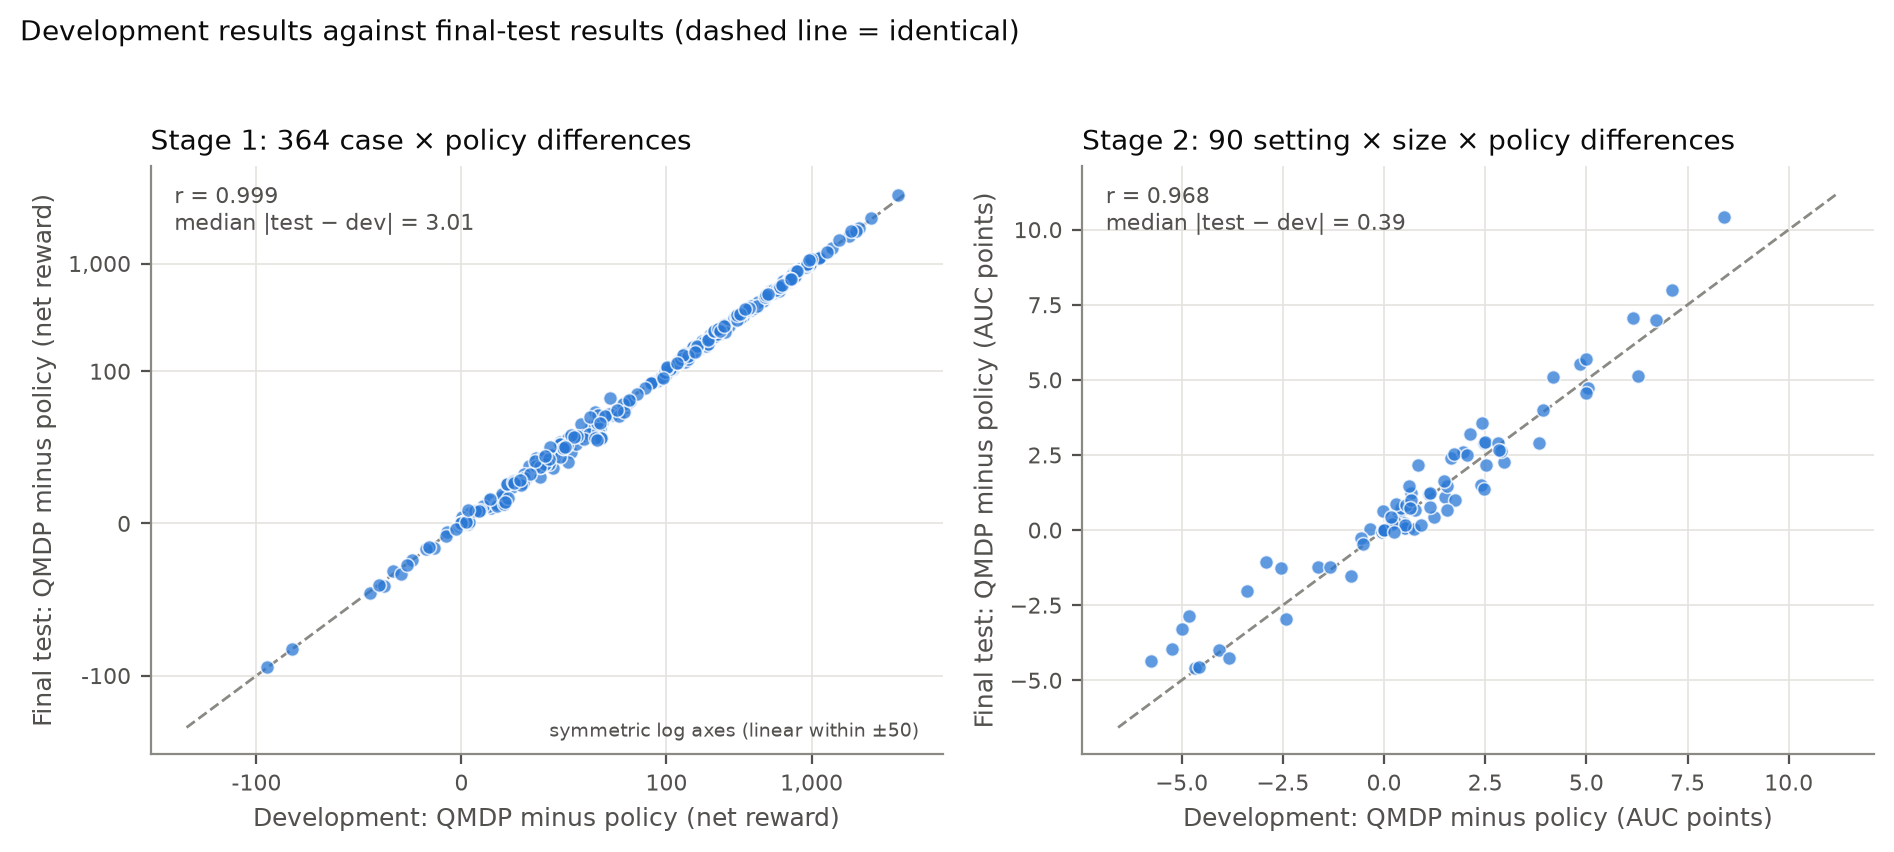

In [15]:
show('fig8_development_vs_final_test', 950)

**Observed:** QMDP's differences against every rival line up closely between development and the final test (r = 0.999 in Stage 1, 0.968 in Stage 2). The development pattern, including the Lapse losses and the near-tie with Greedy + rest, carries over to new people and new images. The Markov β = 2 loss at 200 labels was −0.52 in development (not significant with 10 seeds) and −0.46 on the test (significant with 20).

## 5. Extra metrics from the project description (exploratory)
The project description also lists the number of unnecessary interruptions, the accumulated cognitive burden, and the information gained per interaction and per unit of human effort. None of these was a planned test, so they were **defined after the final test** and are reported as descriptive results only: means and 95% paired bootstrap intervals, no p-values. They come from [compute_extra_metrics.py](../scripts/compute_extra_metrics.py), which reads the saved files and runs nothing new.

Definitions (Stage 2 uses the per-call audit of each run; true hidden fatigue F is on the 0–4 scale):
- **Interactions:** questions asked and answered (verify, two-choice or full; a call cut off at the end of a 600-s shift is not counted).
- **Unnecessary interruptions:** questions asked while the person could not answer reliably: true fatigue F ≥ 3, or after the person lapsed (Lapse worlds only).
- **Burden:** the time-weighted mean of the true fatigue over the human seconds used, and the share of those seconds spent at F ≥ 3.
- **Accuracy gain per 100 answers:** (accuracy at 2,400 s − starting accuracy) / interactions × 100. With diminishing returns this ratio favours policies that collect fewer answers, so it is read together with the accuracy results.
- **Stage 1:** bits per interaction (information / questions asked, gold checks included) and bits per human second. Stage 1 saved only per-session totals, not the fatigue at each step, so it has no burden or interruption measure.

In [16]:
spec = importlib.util.spec_from_file_location('extra_metrics', project / 'scripts' / 'compute_extra_metrics.py')
extra = importlib.util.module_from_spec(spec)
spec.loader.exec_module(extra)
extra.main()   # reads the saved final-test files only
extra_folder = final / 'extra_metrics'
e2 = pd.read_csv(extra_folder / 'stage2_summary.csv')
keep = ['qmdp', 'rest_threshold', 'myopic', 'blind', 'two_choice', 'verify']
labels = {'interactions': 'Interactions per run', 'pauses': 'Pauses per run', 'rest_share': 'Share of time pausing',
          'unnecessary': 'Unnecessary interruptions per run', 'unnecessary_share': 'Share of interactions that were unnecessary',
          'mean_fatigue': 'Burden: time-weighted mean fatigue (0-4)', 'time_high_fatigue': 'Burden: share of time at F >= 3',
          'wrong_answers': 'Wrong answers per run', 'gain_per_100_answers': 'Accuracy gain per 100 answers (points)'}
for metric, title in labels.items():
    display(Markdown(f'**{title}** (200 starting labels, mean of 20 seeds)'))
    table = e2[(e2.seed_size == 200) & e2.policy.isin(keep)].pivot(index='setting', columns='policy', values=metric)[keep]
    display(table.rename(columns=NAMES).round(3))

wrote fig9_interruptions_and_burden
wrote ['fig9_interruptions_and_burden.pdf', 'fig9_interruptions_and_burden.png', 'stage1_qmdp_vs_rivals.csv', 'stage1_summary.csv', 'stage2_qmdp_vs_rivals.csv', 'stage2_run_metrics.csv', 'stage2_summary.csv']


**Interactions per run** (200 starting labels, mean of 20 seeds)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always 2-choice,Always verify
setting,,,,,,
FALCON1,2041.30,1728.60,1883.90,1388.95,1129.60,2064.10
Lapse1:forced,2053.75,2008.40,1535.40,1109.75,1000.05,1714.10
Lapse1:forced_seconds,2032.85,1898.00,1505.80,917.05,965.95,1705.00
Markov1,2157.20,2186.65,1671.15,1199.25,1042.70,1842.90
Markov2,2179.10,2269.15,1662.30,1187.85,1023.85,1805.35
None0,3514.90,3514.90,3514.90,3514.90,2377.45,3742.25


**Pauses per run** (200 starting labels, mean of 20 seeds)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always 2-choice,Always verify
setting,,,,,,
FALCON1,0.00,32.2,0.0,0.0,0.0,0.0
Lapse1:forced,17.40,45.9,0.0,0.0,0.0,0.0
Lapse1:forced_seconds,17.70,38.2,0.0,0.0,0.0,0.0
Markov1,15.45,41.2,0.0,0.0,0.0,0.0
Markov2,16.25,64.2,0.0,0.0,0.0,0.0
None0,0.00,0.0,0.0,0.0,0.0,0.0


**Share of time pausing** (200 starting labels, mean of 20 seeds)

... (9 outputs left out)

**Wrong answers per run** (200 starting labels, mean of 20 seeds)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always 2-choice,Always verify
setting,,,,,,
FALCON1,82.90,79.40,88.40,81.75,57.45,88.30
Lapse1:forced,641.75,639.70,407.20,266.15,210.20,476.90
Lapse1:forced_seconds,604.00,630.85,443.20,319.90,322.95,445.05
Markov1,76.50,69.45,87.90,79.40,55.10,83.55
Markov2,89.55,55.10,103.65,124.85,100.55,102.70
None0,55.20,55.20,55.20,55.20,54.85,47.40


**Accuracy gain per 100 answers (points)** (200 starting labels, mean of 20 seeds)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always 2-choice,Always verify
setting,,,,,,
FALCON1,0.440,0.504,0.477,0.671,0.835,0.422
Lapse1:forced,-0.169,-0.100,0.143,0.504,0.602,-0.038
Lapse1:forced_seconds,-0.121,-0.136,0.045,0.120,0.163,0.015
Markov1,0.417,0.435,0.541,0.746,0.894,0.468
Markov2,0.420,0.438,0.525,0.709,0.823,0.461
None0,0.263,0.263,0.263,0.263,0.424,0.220


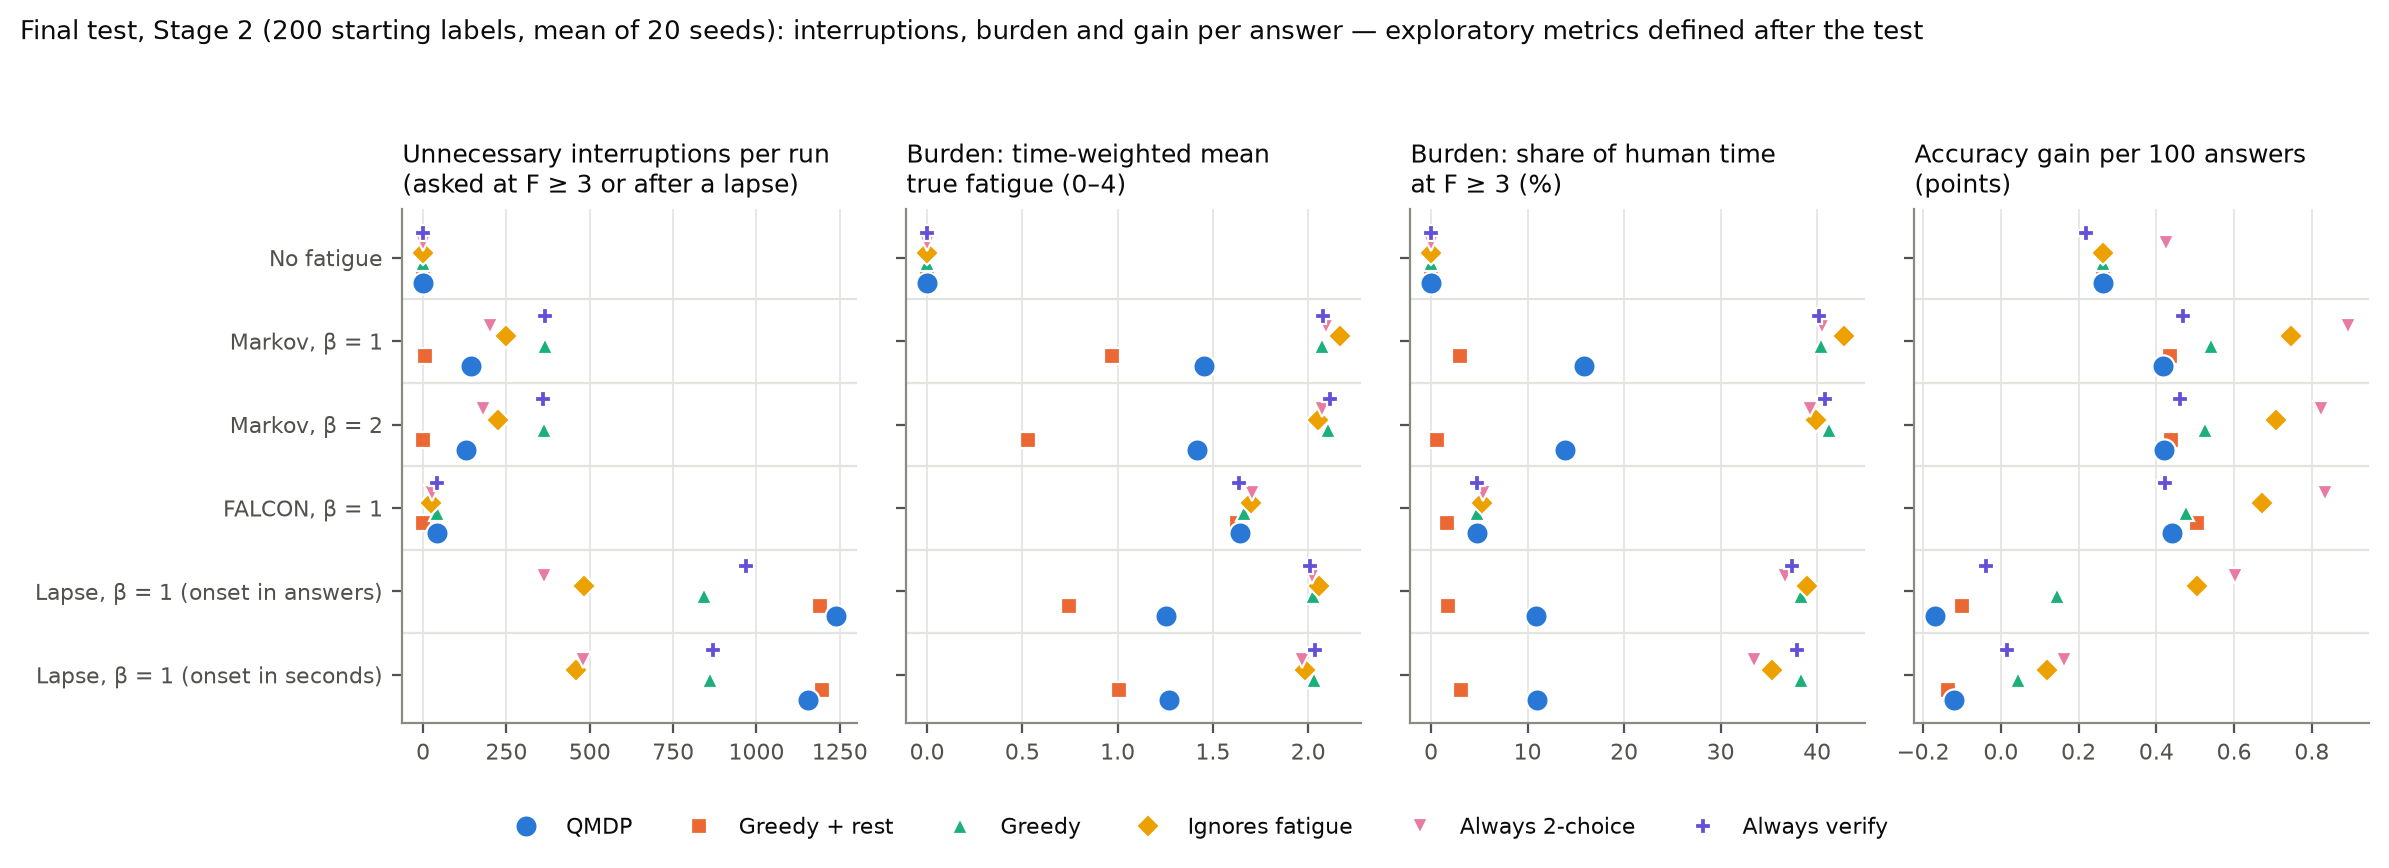

**QMDP minus rival, 200 starting labels (95% paired bootstrap interval; descriptive)**

,setting,seed_size,rival,metric,qmdp_minus_rival,ci_low,ci_high
102,FALCON1,200,Greedy + rest,unnecessary,42.350,16.800,69.750
106,FALCON1,200,Greedy + rest,wrong_answers,3.500,-2.100,9.350
107,FALCON1,200,Greedy + rest,mean_fatigue,0.017,-0.000,0.036
108,FALCON1,200,Greedy + rest,time_high_fatigue,0.031,0.008,0.057
124,FALCON1,200,Ignores fatigue,unnecessary,18.450,5.699,32.350
...,...,...,...,...,...,...,...
1120,None0,200,Ignores fatigue,time_high_fatigue,0.000,0.000,0.000
1136,None0,200,Always verify,unnecessary,0.000,0.000,0.000
1140,None0,200,Always verify,wrong_answers,7.800,3.950,11.700
1141,None0,200,Always verify,mean_fatigue,0.000,0.000,0.000


In [17]:
display(Image(filename=str(extra_folder / 'fig9_interruptions_and_burden.png'), width=1000))
c2 = pd.read_csv(extra_folder / 'stage2_qmdp_vs_rivals.csv')
shown = c2[(c2.seed_size == 200) & c2.rival.isin(['rest_threshold', 'blind', 'verify'])
           & c2.metric.isin(['unnecessary', 'mean_fatigue', 'time_high_fatigue', 'wrong_answers'])]
display(Markdown('**QMDP minus rival, 200 starting labels (95% paired bootstrap interval; descriptive)**'))
display(shown.assign(rival=lambda d: d.rival.map(NAMES)).round(3))

**Observed (Stage 2):**
- With Markov fatigue, QMDP interrupts highly fatigued people far less than the policies that never pause (about 130–145 questions per run at F ≥ 3, against about 180–370), and keeps the mean fatigue lower (about 1.4 against 2.1).
- Greedy + rest does much better on burden: it almost never asks at F ≥ 3 (about 1–6 per run), keeps the mean fatigue at 0.5–1.0 and spends 1–3% of the time at F ≥ 3 (QMDP 14–16%). It pauses about 2.5 to 4 times as often as QMDP (41–64 pauses, 17–27% of the time, against 15–16 pauses, about 7%) and still collects as many answers.
- In both Lapse worlds most interruptions come after the lapse, for every policy; QMDP and Greedy + rest have the most (about 1,150–1,240 per run) because they ask the most questions.
- In FALCON, fatigue rarely reaches 3 for any policy, and QMDP does not pause at all.
- QMDP has the lowest or nearly the lowest accuracy gain per 100 answers, as expected for the policy that asks the most questions.

In [18]:
e1 = pd.read_csv(extra_folder / 'stage1_summary.csv')
cases = ['no_fatigue', 'Markov_beta_1', 'Markov_beta_3', 'FALCON_beta_1', 'FALCON_beta_3', 'Lapse_beta_1', 'Lapse_seconds_beta_1']
cols = ['qmdp', 'rest_threshold', 'myopic', 'blind', 'verify', 'two_choice', 'full', 'dqn']
for metric, title in [('bits_per_interaction', 'Stage 1: bits per interaction'), ('bits_per_second', 'Stage 1: bits per human second')]:
    display(Markdown(f'**{title}** (500 test sessions per case)'))
    display(e1[e1.case.isin(cases)].pivot(index='case', columns='policy', values=metric)[cols].rename(columns=NAMES).round(3))

**Stage 1: bits per interaction** (500 test sessions per case)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always verify,Always 2-choice,Always full,DQN
case,,,,,,,,
FALCON_beta_1,0.894,1.125,1.124,1.568,0.762,1.237,1.705,0.813
FALCON_beta_3,0.830,0.976,0.976,1.155,0.751,1.051,1.115,0.787
Lapse_beta_1,0.487,0.561,0.556,0.669,0.310,0.504,0.748,0.477
Lapse_seconds_beta_1,0.394,0.386,0.381,0.377,0.378,0.352,0.322,0.303
Markov_beta_1,1.181,1.257,1.136,1.542,0.753,1.231,1.613,0.826
Markov_beta_3,1.108,1.064,0.992,1.197,0.735,1.032,1.224,0.804
no_fatigue,1.797,1.797,1.797,1.797,0.805,1.299,2.132,2.099


**Stage 1: bits per human second** (500 test sessions per case)

policy,QMDP,Greedy + rest,Greedy,Ignores fatigue,Always verify,Always 2-choice,Always full,DQN
case,,,,,,,,
FALCON_beta_1,1.059,0.840,0.844,0.631,1.073,0.751,0.429,0.825
FALCON_beta_3,1.035,0.837,0.838,0.422,1.057,0.631,0.233,0.793
Lapse_beta_1,0.397,0.398,0.394,0.236,0.373,0.270,0.148,0.442
Lapse_seconds_beta_1,0.335,0.276,0.279,0.136,0.505,0.197,0.064,0.287
Markov_beta_1,1.042,0.874,0.844,0.657,1.025,0.779,0.392,0.813
Markov_beta_3,1.035,0.848,0.824,0.507,1.007,0.677,0.275,0.785
no_fatigue,1.360,1.360,1.360,1.360,1.312,1.226,1.188,1.196


**Observed (Stage 1):** QMDP gets fewer bits per question than Always full and Ignores fatigue in every fatigue case, and fewer than Greedy and Greedy + rest in FALCON (Markov β = 1: QMDP 1.18, Ignores fatigue 1.54, Always full 1.61). Per human second it is the best or tied with Always verify in Markov and FALCON (Markov β = 1: QMDP 1.04, Always verify 1.03, Greedy + rest 0.87, Greedy 0.84, Ignores fatigue 0.66).

**Interpretation:** QMDP's advantage comes from trading information per question for speed: it asks cheaper questions more often. Pausing is what lowers interruptions and burden, and the tuned rest rule protects the person more than QMDP does at λ = 1, because at that price of a human second QMDP pauses only when it is very sure the person is tired. This is a trade-off to discuss in the report, not a hypothesis test.

## 6. Summary

In [19]:
text = (figures / 'tables.md').read_text()
display(Markdown(text[text.index('## Table 2'):text.index('## Table 3')]))

## Table 2. Hypotheses on the final test

| Hypothesis | Result | Evidence |
|---|---|---|
| H1: no fatigue, QMDP within 1 SE of the best required baseline | holds | difference 0.00 (SE 0.00) against Ignores fatigue |
| H2: beats all of B1–B8 at β ≥ 1 (Holm) | Markov holds; FALCON partial; Lapse fails | Markov 16/17, FALCON 1/3, core Lapse 0/4, Lapse (seconds) 0/4 |
| H3: lead over greedy grows with β (Markov) | fails | gaps 50.0, 45.4, 39.8, 43.4; slope -2.70 per β [-4.50, -1.02] |
| Robustness: beats greedy under misspecified fatigue (Holm) | 5/6 | fails in the FALCON world |
| Stage 2: better than the named rival (Holm, 12 tests) | not shown | 0 clearly better, 4 clearly worse |



**Observed**
- H1 holds; H2 holds for Markov fatigue, holds only partly for FALCON, and fails for Lapse; H3 fails; QMDP beats greedy in 5 of 6 misspecified worlds.
- Stage 2: QMDP is never clearly better than the rival named in advance, and is clearly worse in 4 of 12 comparisons.
- The final test reproduces the development results closely.
- Exploratory metrics (defined after the test): QMDP gets the most information per human second but less per question than the slower formats; with Markov fatigue it interrupts tired people far less than the policies that never pause, but Greedy + rest keeps people much fresher than QMDP while collecting as many answers.

**Interpretation**
- Tracking hidden fatigue and pausing pays off in information per human second whenever fatigue behaves as QMDP assumes.
- For the classifier, what matters is resting; a tuned rest rule gets the same benefit without belief tracking or planning.
- QMDP is fragile when its fatigue model is wrong (Lapse); this is the main limitation to report.
- At λ = 1, QMDP keeps people working at higher fatigue than a tuned rest rule; the human cost and the price of a human second have to be discussed together.